# Cost of Living Analysis: California vs. La Paz

This notebook follows [plan.md](plan.md) section by section.

**Question:** Where is it more affordable to live: California (US) or La Paz (Bolivia)?

**Hypothesis:** La Paz is cheaper in absolute (nominal USD) terms. Once adjusted for purchasing power parity (PPP) and local incomes, it is *not* cheaper in relative terms.

The data is pulled live when the notebook runs, so the numbers in the text cells match the run of **1 Oct 2026**.

## 0. Setup

In [1]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import wbgapi as wb

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Colour = location, kept fixed across every chart
COLORS = {"California": "#2a78d6", "La Paz / Bolivia": "#eb6834", "United States": "#1baf7a"}
# Basket categories use different slots so they never look like a location
BASKET_COLORS = {"Rent": "#4a3aa7", "Utilities & internet": "#008300",
                 "Transport": "#e34948", "Food & other": "#e87ba4"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

sns.set_theme(style="white", rc={
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Data Sources

| Source | What it gives | Level |
|---|---|---|
| World Bank WDI (`wbgapi`) | PPP factors, exchange rate, GNI per capita (PPP), household consumption, CPI | Country (USA, BOL) |
| BEA via FRED | Regional Price Parity, per-capita personal income and consumption | California and US |
| Numbeo (crowd-sourced) | Rent, utilities, transport, and other monthly costs; average net salary | City |

### 1a. World Bank indicators

In [2]:
WB_INDICATORS = {
    "PA.NUS.PPP":        "ppp_gdp",            # LCU per international $
    "PA.NUS.PRVT.PP":    "ppp_private",        # LCU per international $, private consumption
    "PA.NUS.FCRF":       "fx_official",        # LCU per US$, official rate
    "NY.GDP.PCAP.PP.CD": "gdp_pc_ppp",
    "NY.GNP.PCAP.PP.CD": "gni_pc_ppp",
    "NE.CON.PRVT.PC.KD": "hh_cons_pc_const",   # constant 2015 US$
    "NE.CON.PRVT.PP.CD": "hh_cons_ppp_total",  # PPP, current international $
    "SP.POP.TOTL":       "population",
    "FP.CPI.TOTL.ZG":    "cpi_inflation",
}

raw_wb = (
    wb.data.DataFrame(list(WB_INDICATORS), ["USA", "BOL"], time=range(2015, 2027),
                      numericTimeKeys=True, columns="series")
    .rename(columns=WB_INDICATORS)
    .rename_axis(["iso3", "year"])
    .reset_index()
)
raw_wb["country"] = raw_wb["iso3"].map({"USA": "United States", "BOL": "La Paz / Bolivia"})
raw_wb.tail(6)

,iso3,year,cpi_inflation,hh_cons_pc_const,hh_cons_ppp_total,gdp_pc_ppp,gni_pc_ppp,fx_official,ppp_gdp,ppp_private,population,country
16,USA,2020,1.23,"39,899.00","14,231,353,000,000.00","64,465.30","64,740.00",1.00,1.00,1.00,"331,578,104.00",United States
17,USA,2021,4.70,"43,339.08","16,119,682,000,000.10","71,441.23","71,780.00",1.00,1.00,1.00,"332,100,166.00",United States
18,USA,2022,8.00,"44,387.62","17,690,013,000,000.00","78,008.69","78,470.00",1.00,1.00,1.00,"333,996,304.00",United States
19,USA,2023,4.12,"45,153.58","18,833,149,999,999.90","82,586.78","81,870.00",1.00,1.00,1.00,"336,755,052.00",United States
20,USA,2024,2.95,"46,040.60","19,896,008,999,999.90","86,169.66","85,270.00",1.00,1.00,1.00,"340,003,797.00",United States
21,USA,2025,NaN,NaN,"20,934,352,000,000.00","90,026.52","89,490.00",1.00,1.00,1.00,"341,784,857.00",United States


### 1b. California: BEA series via FRED

The World Bank only has country-level data. California's price level and income come from the Bureau of Economic Analysis (BEA), downloaded from FRED's public CSV endpoint (no API key needed).

In [3]:
FRED_SERIES = {
    "CARPPALL":        "ca_rpp",        # Regional Price Parity, all items (US = 100)
    "CAPCPI":          "ca_income_pc",  # CA per-capita personal income, US$
    "CAPCEPC":         "ca_pce_pc",     # CA per-capita personal consumption expenditures, US$
    "A792RC0A052NBEA": "us_income_pc",  # US per-capita personal income, US$
    "A794RC0A052NBEA": "us_pce_pc",     # US per-capita personal consumption expenditures, US$
}

def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    with urllib.request.urlopen(url, timeout=30) as r:
        s = pd.read_csv(io.BytesIO(r.read()), parse_dates=["observation_date"])
    return s.set_index(s["observation_date"].dt.year)[series_id].rename_axis("year")

raw_fred = pd.DataFrame({name: fred(sid) for sid, name in FRED_SERIES.items()}).loc[2015:]
raw_fred.tail(6)

,ca_rpp,ca_income_pc,ca_pce_pc,us_income_pc,us_pce_pc
year,,,,,
2020,111.94,70098,"47,781.00",59160,42886
2021,111.92,77140,"55,060.00",64683,48465
2022,112.59,77221,"60,460.00",66270,52851
2023,112.19,81318,"64,075.00",70137,55691
2024,110.72,86761,"67,227.00",73636,58285
2025,NaN,90957,"70,076.00",76994,61034


### 1c. City-level daily costs: Numbeo snapshot

Numbeo is **crowd-sourced**, so treat it as indicative, not official. Values were read from numbeo.com on 1 Oct 2026 (La Paz updated 24 Sep 2026, LA 1 Oct, SF and Sacramento 30 Sep). Numbeo shows La Paz prices in BOB and California prices in USD.

California has no single Numbeo page, so I use the average of three cities: Los Angeles, San Francisco and Sacramento. For rent I use a 1-bedroom apartment outside the city centre, which is the cheaper and more typical option.

In [4]:
NUMBEO = pd.DataFrame({
    #                          La Paz (BOB)  Los Angeles  San Francisco  Sacramento   (US$)
    "rent_1br_outside":       [2000.00,      2413.33,     2618.75,       1559.09],
    "utilities":              [275.00,        283.91,      214.89,        230.45],
    "internet":               [220.00,         80.07,       76.29,         69.08],
    "transport_pass":         [200.00,        105.00,       95.00,        100.00],
    "monthly_costs_ex_rent":  [3566.90,      1489.00,     1514.60,       1337.40],
    "net_salary":             [2975.00,      4036.85,     6746.84,       4689.17],
}, index=["La Paz", "Los Angeles", "San Francisco", "Sacramento"])

# Numbeo shows La Paz's single-person costs as "$323.8 (Bs.3,566.9)", which implies its USD conversion rate
FX_NUMBEO_BOB = 3566.90 / 323.80
NUMBEO

,rent_1br_outside,utilities,internet,transport_pass,monthly_costs_ex_rent,net_salary
La Paz,"2,000.00",275.00,220.00,200.00,"3,566.90","2,975.00"
Los Angeles,"2,413.33",283.91,80.07,105.00,"1,489.00","4,036.85"
San Francisco,"2,618.75",214.89,76.29,95.00,"1,514.60","6,746.84"
Sacramento,"1,559.09",230.45,69.08,100.00,"1,337.40","4,689.17"


## 2. Cleaning

### 2a. Date range and merge

The window is the **most recent 5 years where every series exists for both countries and for California**. I build one tidy table keyed on `location` and `year`.

In [5]:
REQUIRED_WB = ["ppp_private", "fx_official", "gni_pc_ppp", "hh_cons_ppp_total", "population"]
REQUIRED_FRED = list(FRED_SERIES.values())

wb_complete = raw_wb.dropna(subset=REQUIRED_WB).groupby("year")["iso3"].nunique().eq(2)
fred_complete = raw_fred[REQUIRED_FRED].notna().all(axis=1)
complete_years = sorted(set(wb_complete[wb_complete].index) & set(fred_complete[fred_complete].index))
YEARS = complete_years[-5:]
print("Analysis window:", YEARS)

Analysis window: [2020, 2021, 2022, 2023, 2024]


### 2b. Missing values

Linear interpolation inside each location's series. Gaps at the start or end are filled forward or backward and flagged. Every imputed cell is recorded in `imputation_log`.

In [6]:
imputation_log = []

def impute(df, group_col, value_cols):
    df = df.sort_values([group_col, "year"]).copy()
    for col in value_cols:
        for key, idx in df.groupby(group_col).groups.items():
            s = df.loc[idx, col]
            missing = s.isna()
            if not missing.any():
                continue
            interp = s.interpolate(method="linear", limit_area="inside")
            filled = interp.ffill().bfill()
            for i in s[missing].index:
                method = "linear" if pd.notna(interp[i]) else "edge-fill (flagged)"
                imputation_log.append({"location": key, "year": df.at[i, "year"],
                                       "column": col, "value": filled[i], "method": method})
            df.loc[idx, col] = filled
    return df

wb_window = raw_wb[raw_wb["year"].isin(YEARS)]
wb_window = impute(wb_window, "country", [c for c in WB_INDICATORS.values()])
fred_window = impute(raw_fred.loc[YEARS].reset_index().assign(loc="California"), "loc", REQUIRED_FRED)

print(f"{len(imputation_log)} value(s) imputed")
pd.DataFrame(imputation_log)

0 value(s) imputed


""


### 2c. Transformations

The goal is to put all three locations on **the same World Bank concepts**, in PPP-adjusted international $:

- **Price level** (US = 1.00): for a country, `PPP factor (private consumption) ÷ market exchange rate`. For California, `BEA RPP ÷ 100`.
- **Income per person**: GNI per capita, PPP. California's value is the US figure × (CA ÷ US personal income) ÷ CA price level. This uses BEA only for California's position *relative* to the US.
- **Cost of living per person**: household consumption per capita, PPP, scaled for California the same way using BEA consumption data.
- **Share of income left over** = 1 − cost of living ÷ income. This is the macro version of disposable income.

In [7]:
c = wb_window.copy()
c["price_level"] = c["ppp_private"] / c["fx_official"]
c["income_ppp"] = c["gni_pc_ppp"]
c["cost_ppp"] = c["hh_cons_ppp_total"] / c["population"]
c["inflation"] = c["cpi_inflation"]

us = c[c["country"] == "United States"].set_index("year")
f = fred_window.set_index("year")
ca = pd.DataFrame({
    "country": "California",
    "price_level": f["ca_rpp"] / 100,
    "income_ppp": us["income_ppp"] * (f["ca_income_pc"] / f["us_income_pc"]) / (f["ca_rpp"] / 100),
    "cost_ppp": us["cost_ppp"] * (f["ca_pce_pc"] / f["us_pce_pc"]) / (f["ca_rpp"] / 100),
    "inflation": np.nan,  # no state CPI in this dataset
}).reset_index()

cols = ["country", "year", "price_level", "income_ppp", "cost_ppp", "inflation"]
tidy = pd.concat([c[cols], ca[cols]]).rename(columns={"country": "location"}).reset_index(drop=True)
tidy["left_over_ppp"] = tidy["income_ppp"] - tidy["cost_ppp"]
tidy["left_over_share"] = tidy["left_over_ppp"] / tidy["income_ppp"]
tidy["income_to_cost"] = tidy["income_ppp"] / tidy["cost_ppp"]
tidy.sort_values(["location", "year"])

,location,year,price_level,income_ppp,cost_ppp,inflation,left_over_ppp,left_over_share,income_to_cost
10,California,2020,1.12,"68,525.05","42,716.85",NaN,"25,808.20",0.38,1.60
11,California,2021,1.12,"76,487.95","49,271.46",NaN,"27,216.49",0.36,1.55
12,California,2022,1.13,"81,211.67","53,814.31",NaN,"27,397.36",0.34,1.51
13,California,2023,1.12,"84,603.98","57,350.73",NaN,"27,253.25",0.32,1.48
14,California,2024,1.11,"90,741.21","60,959.73",NaN,"29,781.47",0.33,1.49
0,La Paz / Bolivia,2020,0.37,"9,490.00","6,585.05",0.94,"2,904.95",0.31,1.44
1,La Paz / Bolivia,2021,0.35,"10,970.00","7,448.58",0.74,"3,521.42",0.32,1.47
2,La Paz / Bolivia,2022,0.33,"12,000.00","8,536.06",1.75,"3,463.94",0.29,1.41
3,La Paz / Bolivia,2023,0.33,"12,590.00","8,966.53",2.58,"3,623.47",0.29,1.40
4,La Paz / Bolivia,2024,0.34,"12,630.00","9,171.06",5.10,"3,458.94",0.27,1.38


### 2d. Monthly basket from Numbeo (one person, 1-bedroom apartment)

I group the Numbeo items into four categories. *Food & other* is Numbeo's monthly costs excluding rent, minus the utilities, internet and transport items that are listed separately.

Bolivia currently has an official exchange rate of 6.91 BOB/US$ and a much weaker market rate, about 11.0 implied by Numbeo. I convert at both rates.

In [8]:
n = NUMBEO.copy()
n["Rent"] = n["rent_1br_outside"]
n["Utilities & internet"] = n["utilities"] + n["internet"]
n["Transport"] = n["transport_pass"]
n["Food & other"] = n["monthly_costs_ex_rent"] - n["Utilities & internet"] - n["Transport"]
CATS = list(BASKET_COLORS)

latest = tidy.sort_values("year").groupby("location").last()
FX_OFFICIAL = wb_window.query("iso3 == 'BOL'").sort_values("year")["fx_official"].iloc[-1]
PPP_BOB = raw_wb.query("iso3 == 'BOL'").dropna(subset=["ppp_private"]).sort_values("year")["ppp_private"].iloc[-1]
CA_PRICE = latest.loc["California", "price_level"]

ca_city = n.loc[["Los Angeles", "San Francisco", "Sacramento"], CATS + ["net_salary"]].mean()
lp = n.loc["La Paz", CATS + ["net_salary"]]

basket = pd.DataFrame({
    "La Paz (BOB)":               lp,
    "La Paz (US$ @ official)":    lp / FX_OFFICIAL,
    "La Paz (US$ @ market)":      lp / FX_NUMBEO_BOB,
    "La Paz (PPP intl $)":        lp / PPP_BOB,
    "California (US$)":           ca_city,
    "California (PPP intl $)":    ca_city / CA_PRICE,
}).T
basket["Total costs"] = basket[CATS].sum(axis=1)
basket["Left over"] = basket["net_salary"] - basket["Total costs"]
basket["Left over %"] = basket["Left over"] / basket["net_salary"] * 100
print(f"Official {FX_OFFICIAL:.2f} BOB/US$ | Numbeo-implied market {FX_NUMBEO_BOB:.2f} | "
      f"PPP {PPP_BOB:.3f} BOB/intl $ | CA price level {CA_PRICE:.3f}")
basket.round(0)

Official 6.91 BOB/US$ | Numbeo-implied market 11.02 | PPP 2.699 BOB/intl $ | CA price level 1.107


,Rent,Utilities & internet,Transport,Food & other,net_salary,Total costs,Left over,Left over %
La Paz (BOB),"2,000.00",495.00,200.00,"2,872.00","2,975.00","5,567.00","-2,592.00",-87.00
La Paz (US$ @ official),289.00,72.00,29.00,416.00,431.00,806.00,-375.00,-87.00
La Paz (US$ @ market),182.00,45.00,18.00,261.00,270.00,505.00,-235.00,-87.00
La Paz (PPP intl $),741.00,183.00,74.00,"1,064.00","1,102.00","2,062.00",-960.00,-87.00
California (US$),"2,197.00",318.00,100.00,"1,029.00","5,158.00","3,644.00","1,514.00",29.00
California (PPP intl $),"1,984.00",287.00,90.00,929.00,"4,658.00","3,291.00","1,367.00",29.00


## 3. Charts

### Chart 1: Price levels over the 5-year window

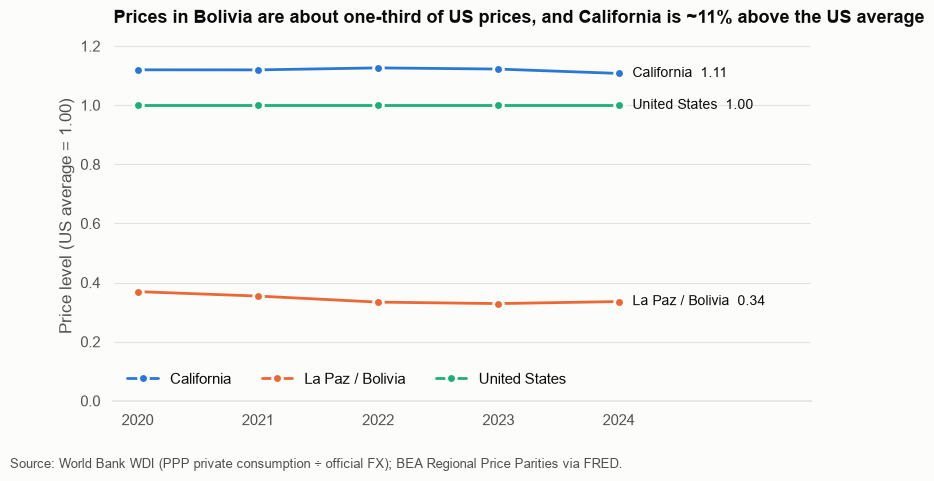

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for loc, g in tidy.groupby("location"):
    g = g.sort_values("year")
    ax.plot(g["year"], g["price_level"], color=COLORS[loc], lw=2, marker="o", ms=7,
            mec="#fcfcfb", mew=2, label=loc)
    last = g.iloc[-1]
    ax.annotate(f"{loc}  {last['price_level']:.2f}", (last["year"], last["price_level"]),
                xytext=(10, 0), textcoords="offset points", va="center", color=INK, fontsize=10)

ax.set_ylim(0, 1.25)
ax.set_xticks(YEARS)
ax.set_xlim(YEARS[0] - 0.2, YEARS[-1] + 1.6)
ax.set_ylabel("Price level (US average = 1.00)")
ax.set_title("Prices in Bolivia are about one-third of US prices, and California is ~11% above the US average")
ax.legend(frameon=False, loc="lower left", ncols=3)
fig.text(0.01, -0.03, "Source: World Bank WDI (PPP private consumption ÷ official FX); BEA Regional Price Parities via FRED.",
         color=INK_2, fontsize=9)
plt.show()

### Chart 2: PPP-adjusted income vs. cost of living (monthly, one person)

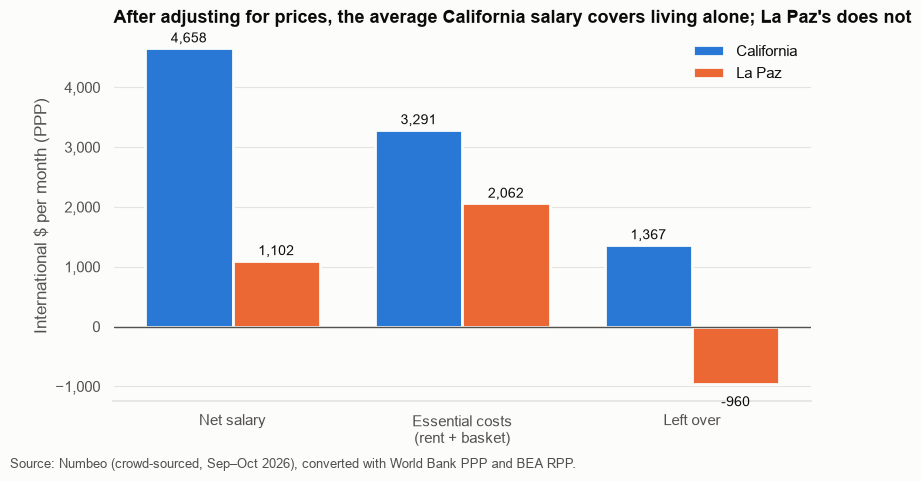

In [10]:
measures = {"net_salary": "Net salary", "Total costs": "Essential costs\n(rent + basket)", "Left over": "Left over"}
rows = {"California": "California (PPP intl $)", "La Paz / Bolivia": "La Paz (PPP intl $)"}

x = np.arange(len(measures))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (loc, row) in enumerate(rows.items()):
    vals = basket.loc[row, list(measures)].values
    bars = ax.bar(x + (i - 0.5) * w, vals, w, color=COLORS[loc], label=loc.replace(" / Bolivia", ""),
                  edgecolor="#fcfcfb", linewidth=2)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:,.0f}", (b.get_x() + b.get_width() / 2, v),
                    xytext=(0, 4 if v >= 0 else -16), textcoords="offset points",
                    ha="center", fontsize=10, color=INK)

ax.axhline(0, color=INK_2, lw=1)
ax.set_xticks(x, measures.values())
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_ylabel("International $ per month (PPP)")
ax.set_title("After adjusting for prices, the average California salary covers living alone; La Paz's does not")
ax.legend(frameon=False, loc="upper right")
fig.text(0.01, -0.03, "Source: Numbeo (crowd-sourced, Sep–Oct 2026), converted with World Bank PPP and BEA RPP.",
         color=INK_2, fontsize=9)
plt.show()

### Chart 3: Monthly cost basket, in nominal US$

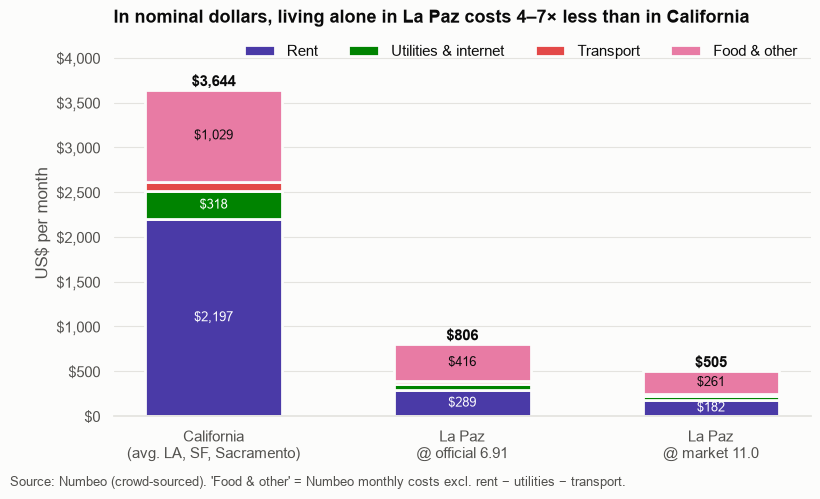

In [11]:
show = ["California (US$)", "La Paz (US$ @ official)", "La Paz (US$ @ market)"]
labels = ["California\n(avg. LA, SF, Sacramento)", "La Paz\n@ official 6.91", f"La Paz\n@ market {FX_NUMBEO_BOB:.1f}"]

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(show))
for cat in CATS:
    vals = basket.loc[show, cat].values
    ax.bar(labels, vals, 0.55, bottom=bottom, color=BASKET_COLORS[cat], label=cat,
           edgecolor="#fcfcfb", linewidth=2)
    for j, (v, b0) in enumerate(zip(vals, bottom)):
        if v > 120:  # label segments that are tall enough to hold text
            ax.text(j, b0 + v / 2, f"${v:,.0f}", ha="center", va="center", fontsize=9.5,
                    color=INK if cat == "Food & other" else "white")
    bottom += vals
for j, tot in enumerate(bottom):
    ax.text(j, tot + 40, f"${tot:,.0f}", ha="center", fontweight="bold", color=INK)

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_ylabel("US$ per month")
ax.set_title("In nominal dollars, living alone in La Paz costs 4–7× less than in California")
ax.legend(frameon=False, ncols=4, loc="upper right")
ax.set_ylim(0, bottom.max() * 1.18)
fig.text(0.01, -0.03, "Source: Numbeo (crowd-sourced). 'Food & other' = Numbeo monthly costs excl. rent − utilities − transport.",
         color=INK_2, fontsize=9)
plt.show()

## 4. Analysis: does the gap hold across all 5 years?

The Numbeo snapshot covers a single month. To check the result across the window, I use the macro data: income per person minus household consumption per person, both in PPP $.

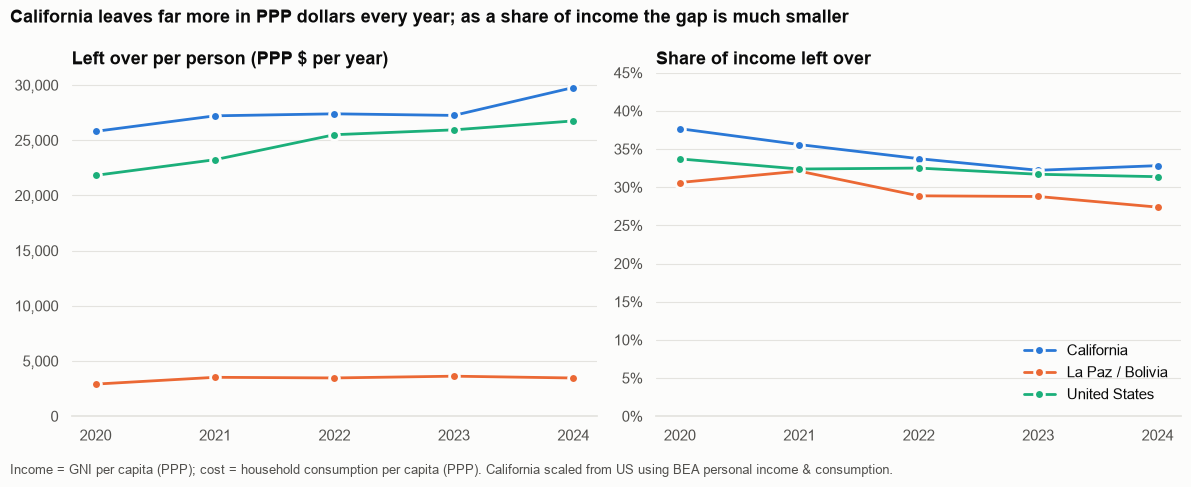

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

for loc, g in tidy.groupby("location"):
    g = g.sort_values("year")
    for ax, col in zip(axes, ["left_over_ppp", "left_over_share"]):
        ax.plot(g["year"], g[col], color=COLORS[loc], lw=2, marker="o", ms=7, mec="#fcfcfb", mew=2, label=loc)

axes[0].set_title("Left over per person (PPP $ per year)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_ylim(bottom=0)
axes[1].set_title("Share of income left over")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[1].set_ylim(0, 0.45)
for ax in axes:
    ax.set_xticks(YEARS)
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("California leaves far more in PPP dollars every year; as a share of income the gap is much smaller",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, -0.03, "Income = GNI per capita (PPP); cost = household consumption per capita (PPP). "
         "California scaled from US using BEA personal income & consumption.", color=INK_2, fontsize=9)
fig.tight_layout()
plt.show()

In [13]:
summary = tidy.pivot(index="year", columns="location", values=["left_over_ppp", "left_over_share", "income_to_cost"])
ratio = (summary["left_over_ppp"]["California"] / summary["left_over_ppp"]["La Paz / Bolivia"]).rename("CA ÷ Bolivia, PPP $ left over")
display(summary.round(2))
ratio.round(1).to_frame()

left_over_ppp                                left_over_share  \
location    California La Paz / Bolivia United States      California   
year                                                                    
2020         25,808.20         2,904.95     21,819.94            0.38   
2021         27,216.49         3,521.42     23,241.39            0.36   
2022         27,397.36         3,463.94     25,505.30            0.34   
2023         27,253.25         3,623.47     25,944.63            0.32   
2024         29,781.47         3,458.94     26,752.98            0.33   

                                        income_to_cost                   \
location La Paz / Bolivia United States     California La Paz / Bolivia   
year                                                                      
2020                 0.31          0.34           1.60             1.44   
2021                 0.32          0.32           1.55             1.47   
2022                 0.29          0.33           1.51             1.41   
2023                 0.29          0.32           1.48             1.40   
2024                 0.27          0.31           1.49             1.38   

                        
location United States  
year                    
2020              1.51  
2021              1.48  
2022              1.48  
2023              1.46  
2024              1.46

,"CA ÷ Bolivia, PPP $ left over"
year,
2020,8.90
2021,7.70
2022,7.90
2023,7.50
2024,8.60


## 5. Interpreting the Results

### What the data shows

**1. In absolute terms, La Paz is much cheaper.** In 2024, Bolivia's price level is **0.34** (US = 1.00) and California's is **1.11** (Chart 1). Living alone in a 1-bedroom apartment costs **\$3,644/month** in California compared with **\$806** in La Paz at the official exchange rate, or **\$505** at the market rate. That makes California 4.5–7.2× more expensive (Chart 3). Rent drives most of the gap: about \$2,200 compared with \$180–290.

**2. Relative to local incomes, La Paz is not cheaper.**
- **Monthly snapshot (Chart 2):** In PPP dollars, the average California net salary covers essential costs and leaves about **1,370 intl \$/month** (29% of salary). The average La Paz net salary (Bs 2,975) does **not** cover living alone in a 1-bedroom apartment: the shortfall is about **960 intl \$/month**, with costs 87% higher than the salary.
- **Over 5 years (Chart 4):** California keeps **32–38%** of income after household consumption, compared with **27–32%** for Bolivia. California is ahead in every year from 2020 to 2024. In PPP dollars per person, that is **7.5–8.9× more** left over in California. Bolivia's share has been falling since 2021.

### Verdict: the hypothesis is **supported**

This matches the *Supports* case in the plan. California has higher costs but leaves more PPP-adjusted disposable income. On purely financial terms, California is the more affordable place relative to what people earn. As a **share of income**, the gap is smaller (about 5–6 percentage points) than in PPP dollars, so most of California's advantage comes from much higher incomes rather than a much lower cost burden.

### Caveats
- **La Paz is approximated by Bolivia** in the 5-year data. The World Bank has no city-level figures, and INE Bolivia department data was not added in this version.
- **Numbeo is crowd-sourced** and its average salary may not represent the city. A single average salary paying for a 1-bedroom alone is also a strict test, since sharing housing is common in both places.
- **Income concepts are approximations.** GNI per capita is not household disposable income, because it includes depreciation and corporate profits. California's values are scaled from US figures using BEA ratios.
- **Exchange rate:** Bolivia's official 6.91 BOB/US$ is well above its market value (~11.0). 2025 data, which includes 19.5% Bolivian inflation, falls outside the complete-data window. The 2026 snapshot uses the 2025 PPP factor.
- **This is a financial comparison only.** It ignores visas, taxes on specific incomes, healthcare and quality of life.